# Visualize preprocessing outputs

Sanity-check `track_cotracker.py` and `landmarks_mediapipe.py` outputs on
an already-processed video. Pure visualization/QA — does not reprocess
anything.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

## Config — edit these

In [2]:
# Path relative to this notebook's location (preprocess/); adjust if run from elsewhere.
data_dir = "../local_dev/tmp/dataset"
video_id = "58DPO_8Bd88_3"

video_dir = os.path.join(data_dir, video_id)
images_dir = os.path.join(video_dir, "images")
mediapipe_dir = os.path.join(video_dir, "mediapipe")

## Load tracks + visibility

In [3]:
pred_tracks = torch.load(
    os.path.join(video_dir, "pred_tracks.pt"), weights_only=True, map_location="cpu"
).numpy()  # [1, T, P, 2] xy pixel coords
pred_visibility = torch.load(
    os.path.join(video_dir, "pred_visibility.pt"), weights_only=True, map_location="cpu"
).numpy()  # [1, T, P] bool

n_frames = pred_tracks.shape[1]
print(f"{n_frames} frames, {pred_tracks.shape[2]} points")


def load_frame(idx: int) -> np.ndarray:
    return np.array(Image.open(os.path.join(images_dir, f"{idx}.jpg")))

71 frames, 853 points


## Tracks overlaid on a few frames

Visible points in green, occluded in faded red.

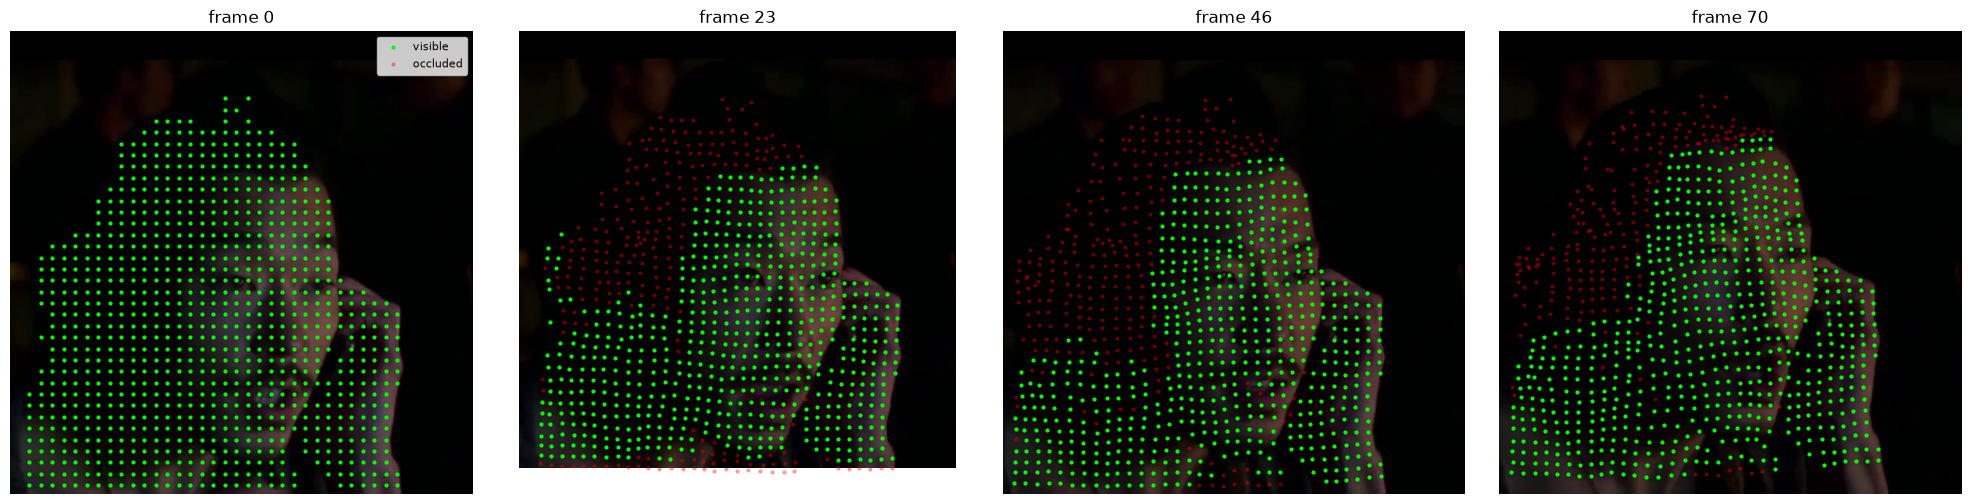

In [4]:
sample_frames = np.linspace(0, n_frames - 1, min(4, n_frames), dtype=int)

fig, axes = plt.subplots(1, len(sample_frames), figsize=(5 * len(sample_frames), 5))
axes = np.atleast_1d(axes)
for ax, t in zip(axes, sample_frames):
    ax.imshow(load_frame(t))
    xy = pred_tracks[0, t]
    vis = pred_visibility[0, t]
    ax.scatter(*xy[vis].T, s=4, c="lime", label="visible")
    ax.scatter(*xy[~vis].T, s=4, c="red", alpha=0.3, label="occluded")
    ax.set_title(f"frame {t}")
    ax.axis("off")
axes[0].legend(loc="upper right", fontsize=8)
fig.tight_layout()

## Track motion over time

Grid of every Nth frame — tracks should drift smoothly, not jump/collapse.

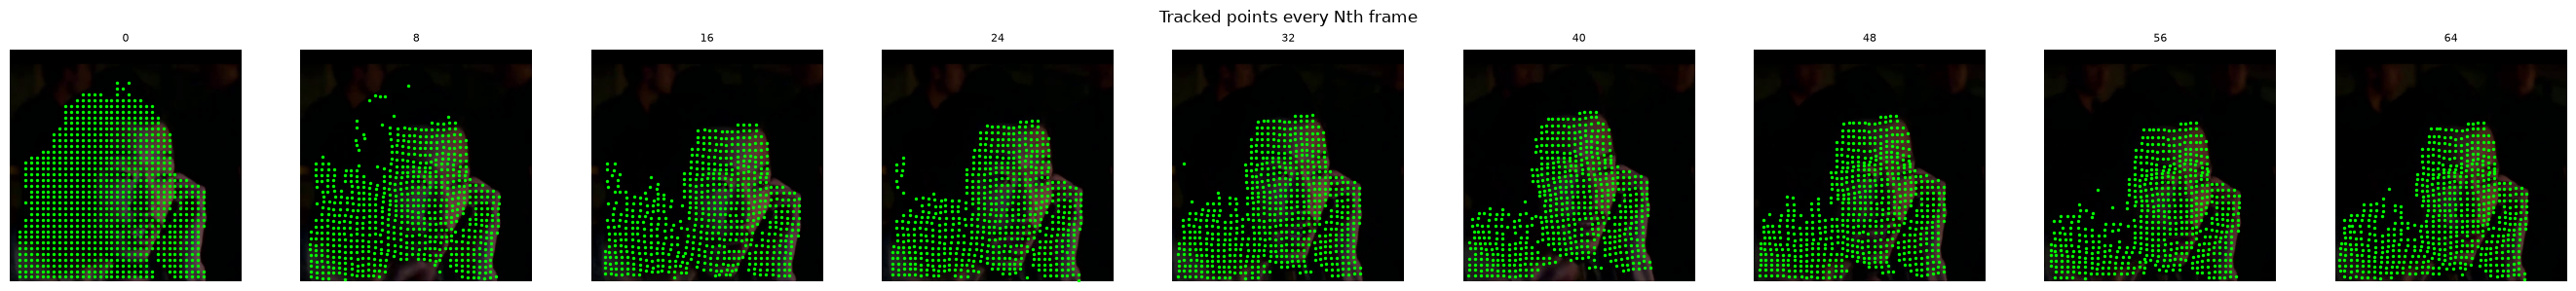

In [5]:
step = max(1, n_frames // 8)
grid_frames = list(range(0, n_frames, step))

fig, axes = plt.subplots(1, len(grid_frames), figsize=(3 * len(grid_frames), 3))
axes = np.atleast_1d(axes)
for ax, t in zip(axes, grid_frames):
    ax.imshow(load_frame(t))
    vis = pred_visibility[0, t]
    ax.scatter(*pred_tracks[0, t, vis].T, s=2, c="lime")
    ax.set_title(str(t), fontsize=8)
    ax.axis("off")
fig.suptitle("Tracked points every Nth frame")
fig.tight_layout()

## MediaPipe landmarks on one frame

468 normalized landmarks -> pixel coords via image size. Visible in cyan,
occluded in faded orange.

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

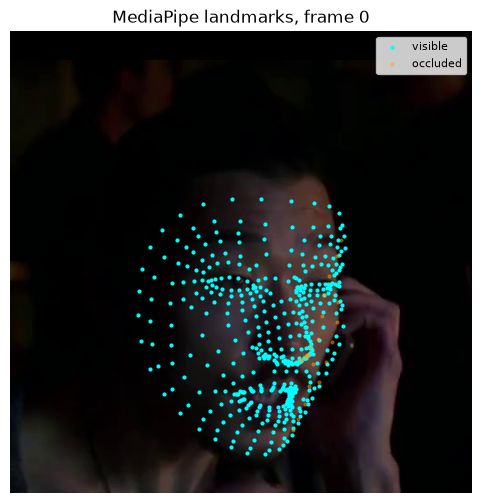

In [6]:
lmk_frame = sample_frames[0]
img = load_frame(lmk_frame)
h, w = img.shape[:2]

mp_lmks = np.load(os.path.join(mediapipe_dir, f"{lmk_frame}.npy"))  # [468, 2] xy in [0, 1]
mp_vis = np.load(os.path.join(mediapipe_dir, f"{lmk_frame}_vis_mask.npy"))  # [468] bool
mp_lmks_px = mp_lmks * np.array([w, h])

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img)
ax.scatter(*mp_lmks_px[mp_vis].T, s=4, c="cyan", label="visible")
ax.scatter(*mp_lmks_px[~mp_vis].T, s=4, c="orange", alpha=0.4, label="occluded")
ax.set_title(f"MediaPipe landmarks, frame {lmk_frame}")
ax.legend(loc="upper right", fontsize=8)
ax.axis("off")

## GSAM mask (optional — skipped if not present)

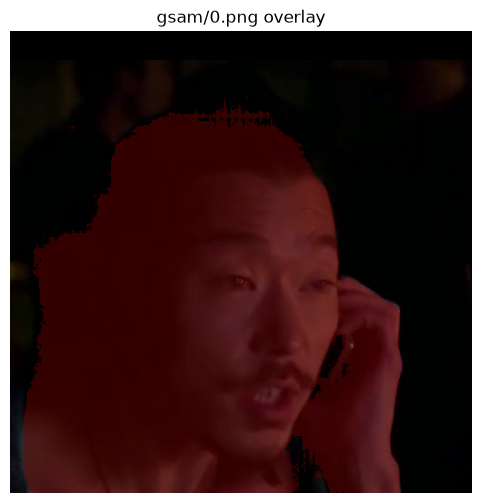

In [7]:
gsam_path = os.path.join(video_dir, "gsam", "0.png")
if os.path.isfile(gsam_path):
    mask = np.array(Image.open(gsam_path).convert("L"))
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(load_frame(0))
    ax.imshow(mask, cmap="jet", alpha=0.4 * (mask > 0))
    ax.set_title("gsam/0.png overlay")
    ax.axis("off")
else:
    print(f"No gsam mask at {gsam_path}, skipping.")

## Sanity checks against the data.py contract

In [8]:
assert pred_tracks.ndim == 4 and pred_tracks.shape[0] == 1 and pred_tracks.shape[-1] == 2
assert pred_tracks.dtype == np.float32
assert pred_visibility.shape[:3] == pred_tracks.shape[:3]
assert pred_visibility.dtype == np.bool_

assert mp_lmks.shape == (468, 2) and mp_lmks.dtype == np.float32
assert mp_lmks.min() >= 0.0 and mp_lmks.max() <= 1.0
assert mp_vis.shape == (468,) and mp_vis.dtype == np.bool_

n_images = len([f for f in os.listdir(images_dir) if f.endswith(".jpg")])
assert n_images == n_frames, f"{n_images} images but {n_frames} tracked frames"

print("All shape/dtype checks passed.")

All shape/dtype checks passed.
